This example guides you through a simple, yet complete, example of how to go from ntuples to training a graph network. In particular it shows how to:
- Read jet constituents from a .root file, build graphs in either the Euclidian or Lund geometries, and store them for later use
- Load graph datasets accounting for event weights, merging multiple samples, and split the data in taining/testing
- Define and train a graph network
- Evaluate the performance of the graph network at the task at hand

A graph is an _unordered_ set of objects, called **nodes**, connected to each other via **edges**:

<img src="images/graph.png" width=200>

Each node $x_i$ and edge $a_{ij}$ can be assigned a (set of) features.

Graphs are a more natural representation of jets compared to tabular (arrays of features) of images: compared to the former, thay lift the limitation of having the number of features fixed for every example, allowing for e.g., using the 4-momenta of constituents directly; compared to the latter, they circumvent the issue of sparsity and are rotationally invariant by construction.

Though there are many ways to represent a jet as a graph, two of them are available in this package:
- So-called spacial graphs, based on the distribution of constituents in the $(\eta,\phi)$ plane. Each constituent is a node, with connections being added between nodes that are closer in $\Delta R=\sqrt{\Delta\eta^2 + \Delta\phi^2}$ then a given threshold:

<img src="images/spacial_graph.png" width=600>

- Lund graphs, based on the Cambridge-Aachen clustering pattern. Starting from the constituents of the jet, these are pairwise clustered together by adding their 4-momenta. The clustering proceeds recursively until all constituents are added together to form the original jet. Keeping track of each merging step, a binary tree is constructed, called the Lund tree:

<img src="images/lund_graph.png" width=800>

At each node (i.e., clustering step) a set of features are calculated, called Lund variables. These are:
- $\Delta = \sqrt{(\eta_i - \eta_j)^2 + (\phi_i -\phi_j)^2}$
- $k_T = \Delta\cdot\min (p_{T,i},p_{T,j})$
- $\psi = \arctan( (y_{lo} - y_{hi})/(\phi_{lo} - \phi_{hi}) )$ (_lo_ and _hi_ being the indices of the highest and lowest pt constituent of the culstered pair, respectively)
- $z = \min(p_{T,i},p_{T,j})/(p_{T,i} + p_{T,j})$
- The invariant mass of the clustered pair

Optionally, the 4-momenta of the clustered pair can be stored as well. Finally, the energy fractions i.e., how much of the energy of a given pseudojet (a node) comes from electrons, muons, photons, or hadrons.

The first step is to load (and process, if neccessary) the graph dataset. This is handled by the `utils.JetGraphProducer` module. The underlying package that we use is [PyTorch Geometric](https://pytorch-geometric.readthedocs.io/en/latest/) (PyG) - an extension of [PyTorch](https://pytorch.org/) that handles graphs.

In [1]:
from utils.JetGraphProducer import JetGraphProducer

# JetGraphProducer processes the ROOT files the first time this name is used.
# Later constructions with the same compatible configuration reuse the cached
# graph chunks in data/processed/.
qcd = JetGraphProducer(
    root="data/",
    output_dataset_name="QCD_test_lund",
    n_store_jets=2,
    # max_events_to_process=100,
    use_lund_decomp=True,
    n_lund_vars=5,
    save_energy_fractions=True,
    save_4vectors_in_lund_tree=False,
    weights="xsec",
    label=0,
    graphs_per_chunk=1000,
    event_batch_size=100,
    num_workers=4,
    worker_prefetch=2,
    verbose=True,
)

`JetGraphProducer` returns a `torch_geometric.data.Dataset`. It behaves much like a list of graphs, while loading graph chunks lazily from disk instead of keeping the complete dataset in memory:

In [2]:
print(qcd[0])

Data(x=[89, 9], edge_index=[2, 176], y=[1], num_nodes=89, num_node_features=9, w=[1])


Each graph has a number of features, the most important ones for now being `.x` and `.edge_index`. The `.x` attribute contains the features of each nodes, stored in a $N_{nodes}\times N_{features}$ dimensional tensor

In [3]:
print(qcd[0].x.shape)
print(qcd[0].x)

torch.Size([89, 9])
tensor([[ 0.0000e+00,  0.0000e+00,  1.0000e+00,  7.8540e-01,  4.6108e-06,
          0.0000e+00,  0.0000e+00,  1.0000e+00,  0.0000e+00],
        [ 0.0000e+00,  0.0000e+00,  1.0000e+00,  7.8540e-01,  1.3957e-01,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00],
        [ 0.0000e+00,  0.0000e+00,  1.0000e+00,  7.8540e-01,  1.3957e-01,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00],
        [ 0.0000e+00,  0.0000e+00,  1.0000e+00,  7.8540e-01,  0.0000e+00,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00],
        [ 0.0000e+00,  0.0000e+00,  1.0000e+00,  7.8540e-01,  1.3957e-01,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00],
        [ 0.0000e+00,  0.0000e+00,  1.0000e+00,  7.8540e-01,  1.3957e-01,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00],
        [ 0.0000e+00,  0.0000e+00,  1.0000e+00,  7.8540e-01,  0.0000e+00,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00],
        [ 0.0000e+00,  0.000

The `.edge_index` attribute encodes node connections. Conceptually these connections form an $N_{nodes}\times N_{nodes}$ adjacency matrix, whose element $a_{ij}$ is 1 when nodes $i$ and $j$ are connected. We can materialize that dense representation for inspection:

In [4]:
from torch_geometric.utils import to_dense_adj

print(to_dense_adj(qcd[0].edge_index))

tensor([[[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 0., 1., 0.],
         [0., 0., 0.,  ..., 1., 0., 1.],
         [0., 0., 0.,  ..., 0., 1., 0.]]])


PyG stores edges sparsely by default. Rather than allocating the full adjacency matrix, it stores a $2\times N_{edges}$ tensor: every column contains the source and target node indices of one directed edge. Lund parent–child connections are stored in both directions.

In [5]:
print(qcd[0].edge_index.shape)
print(qcd[0].edge_index)

torch.Size([2, 176])
tensor([[ 4,  5, 45, 45,  0, 45, 46, 46,  1, 46, 47, 47,  3, 47, 48, 48, 17, 19,
         49, 49,  6, 37, 50, 50,  2, 48, 51, 51,  7,  8, 52, 52, 51, 52, 53, 53,
         15, 49, 54, 54, 14, 18, 55, 55, 39, 54, 56, 56, 28, 33, 57, 57, 10, 27,
         58, 58,  9, 53, 59, 59, 12, 55, 60, 60, 21, 44, 61, 61, 26, 56, 62, 62,
         25, 29, 63, 63, 30, 41, 64, 64, 11, 62, 65, 65, 13, 60, 66, 66, 23, 57,
         67, 67, 61, 64, 68, 68, 58, 65, 69, 69, 16, 35, 70, 70, 59, 68, 71, 71,
         63, 69, 72, 72, 67, 71, 73, 73, 20, 38, 74, 74, 50, 72, 75, 75, 66, 70,
         76, 76, 75, 76, 77, 77, 24, 34, 78, 78, 32, 73, 79, 79, 36, 43, 80, 80,
         22, 40, 81, 81, 74, 81, 82, 82, 42, 77, 83, 83, 31, 80, 84, 84, 79, 84,
         85, 85, 83, 85, 86, 86, 82, 86, 87, 87, 78, 87, 88, 88],
        [45, 45,  4,  5, 46, 46,  0, 45, 47, 47,  1, 46, 48, 48,  3, 47, 49, 49,
         17, 19, 50, 50,  6, 37, 51, 51,  2, 48, 52, 52,  7,  8, 53, 53, 51, 52,
         54, 54, 15, 4

For a Lund tree, every clustering step creates a parent with two children. Since each parent–child connection is stored in both directions, an unpruned tree with $N$ nodes has $2(N-1)$ directed edges. We can also plot a Lund graph to get a feel for its structure:

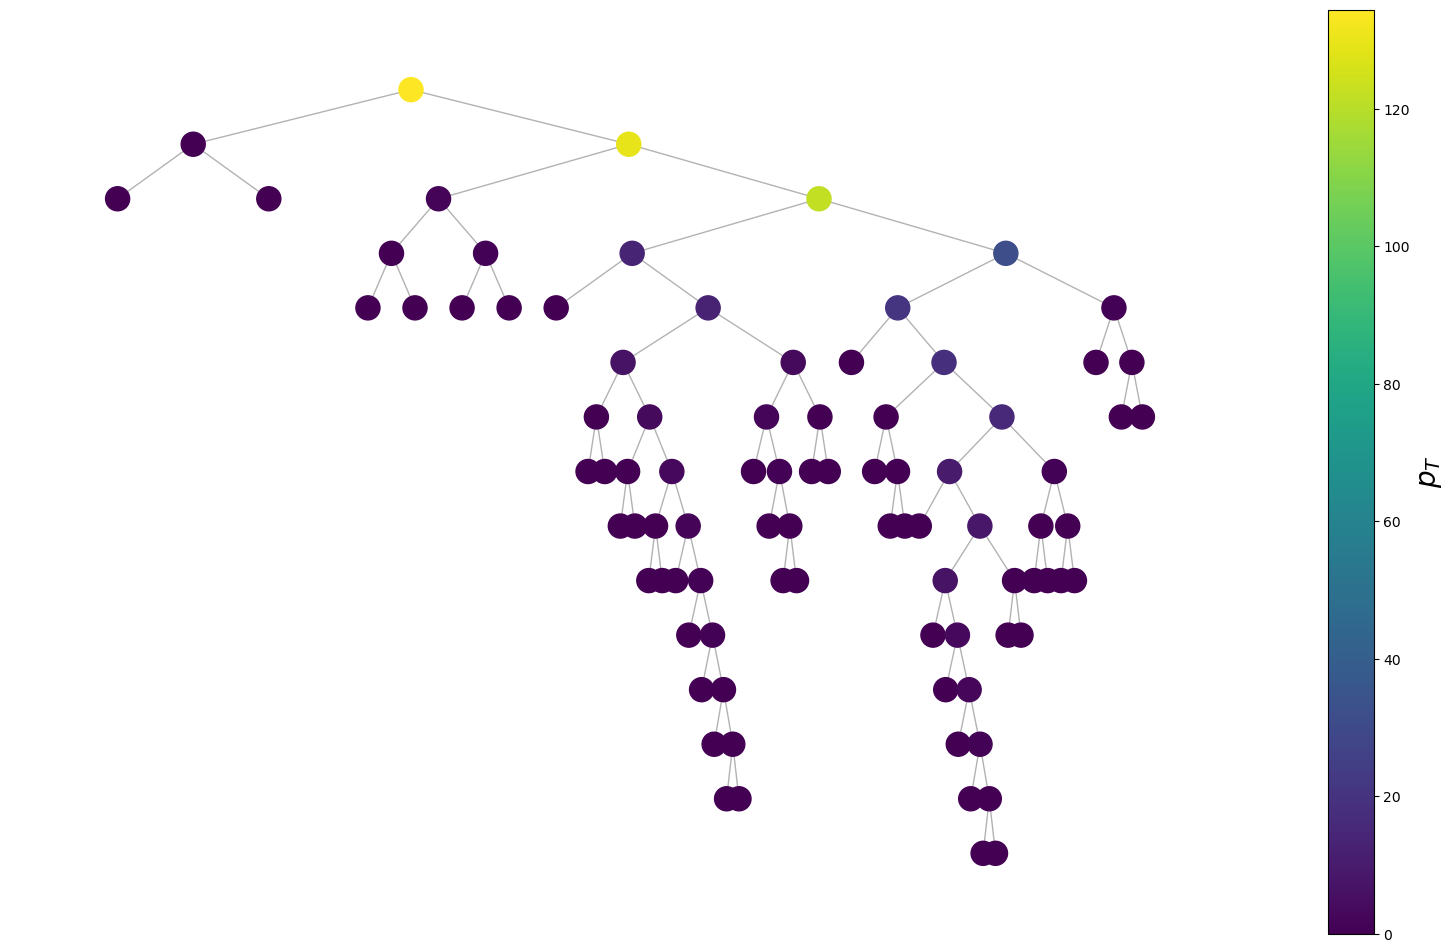

In [6]:
from utils.PlotUtils import plot_tree

# Plot a nice Lund tree
plot_tree(qcd[0], 4, "$p_T$", "myTree", show=True)

The next step is loading data for training. `GraphDataLoader` separates a fixed, reproducible dataset split from the sampling order used within that split. It can:
- Build randomized but reproducible train/validation/test partitions
- Normalize graphs lazily
- Batch graphs
- Shuffle a selected partition each epoch or sample it according to event weights
- Concatenate multiple processed datasets when needed

Normalization statistics must be computed from the training partition only, so we first create an unnormalized statistics loader.

In [7]:
import torch
from data_loading.graphDataLoader import GraphDataLoader
from utils.LundTreeUtilities import OnTheFlyNormalizer
from tqdm import tqdm

paths = [["data/", "QCD_test_lund"]]
train_window = [[0.0, 0.7]]
test_window = [[0.7, 1.0]]

# A fixed seed mixes possible time-dependent effects before splitting. The
# resulting split_state can be saved and reused in other processes.
stats_loader = GraphDataLoader(
    dataset_paths=paths,
    split_windows=train_window,
    split_seed=12345,
    sampling="sequential",
    batch_size=64,
)
split_state = stats_loader.get_split_state()
# torch.save(split_state, "qcd_split.pt")

# Compute event-weighted node statistics from the training partition only.
n_features = qcd[0].num_node_features
feature_sum = torch.zeros(n_features, dtype=torch.float64)
total_node_weight = torch.tensor(0.0, dtype=torch.float64)

for batch in tqdm(stats_loader, desc="Computing training means"):
    node_weights = batch.w.reshape(-1)[batch.batch].to(torch.float64)
    features = batch.x.to(torch.float64)
    feature_sum += (features * node_weights[:, None]).sum(dim=0)
    total_node_weight += node_weights.sum()

means = feature_sum / total_node_weight
variance_sum = torch.zeros_like(means)

for batch in tqdm(stats_loader, desc="Computing training standard deviations"):
    node_weights = batch.w.reshape(-1)[batch.batch].to(torch.float64)
    features = batch.x.to(torch.float64)
    variance_sum += (
        (features - means).square() * node_weights[:, None]
    ).sum(dim=0)

stds = torch.sqrt(variance_sum / total_node_weight)
normalizer = OnTheFlyNormalizer(["x"], means.float(), stds.float())

loader_training = GraphDataLoader(
    dataset_paths=paths,
    split_windows=train_window,
    split_state=split_state,
    sampling="weighted",
    normalizer=normalizer,
    batch_size=64,
)

loader_testing = GraphDataLoader(
    dataset_paths=paths,
    split_windows=test_window,
    split_state=split_state,
    sampling="sequential",
    normalizer=normalizer,
    batch_size=64,
)

Computing training standard deviations: 100%|██████████| 303/303 [00:09<00:00, 31.73it/s]


We are now ready to define and train a graph autoencoder. A sample architecture is provided in `architectures.GraphAE`, but feel free to be creative :) We also define the optimizer

In [8]:
import time
from architectures.GraphAE import graphAE

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = graphAE(
    num_features=qcd[0].num_node_features,
    architecture=(256, 128, 64, 32, 16, 8, 4),
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

We are now ready to train the network. First, we enclose one step of the batched gradient-descent procedure in a function for convenience:

In [9]:
from torch_geometric.utils import batched_negative_sampling

# One batched gradient-descent step.
def train_on_batch(model, batch, optimizer, alpha=1.0):
    model.train()
    batch = batch.to(device)
    x = batch.x
    edges = batch.edge_index

    negative_edges = batched_negative_sampling(edges, batch.batch)
    edges_loss = model.edges_loss(x, edges, negative_edges)
    features_loss = model.features_loss(x, edges)
    loss = edges_loss + alpha * features_loss

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    return edges_loss.detach().item(), features_loss.detach().item()

Then we train while keeping track of the loss. The number of epochs is deliberately very small for a runnable example; a real training campaign will generally require substantially more epochs.

In [10]:
# Train the model
losses = []
losses_edges = []
losses_nodes = []
epochs = 1
alpha = 1

start = time.time()

for epoch in range(epochs):
    for batch in tqdm(loader_training, desc=f"Epoch {epoch}", leave=False):

        loss_edges, loss_features = train_on_batch(model, batch, optimizer, alpha)
        losses.append(loss_edges+alpha*loss_features)
        losses_edges.append(loss_edges)
        losses_nodes.append(alpha*loss_features)

print(f"--> Training completed in {time.time()-start:.2f} seconds")

--> Training completed in 78.80 seconds


We can visualize the evolution of the loss function after the training is complete:

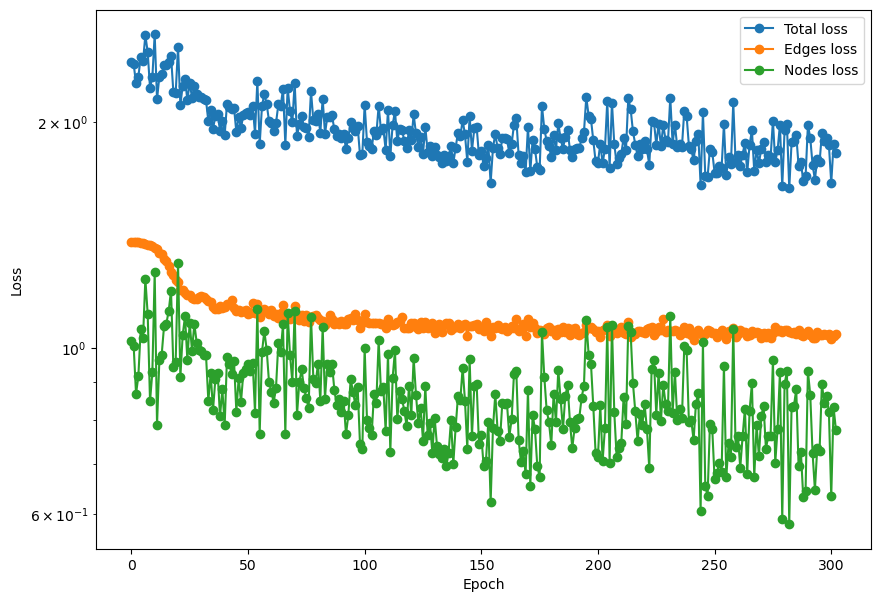

In [11]:
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.figsize': (10, 7)})

plt.plot(losses, label="Total loss", marker="o")
plt.plot(losses_edges, label="Edges loss", marker="o")
plt.plot(losses_nodes, label="Nodes loss", marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.yscale("log")
plt.legend()
plt.show()

Finally, evaluate the reconstruction loss on the held-out QCD partition. This provides a simple data-quality and overfitting check for the autoencoder.

In [12]:
model.eval()
losses_testing_qcd = []

with torch.no_grad():
    for batch in tqdm(loader_testing, desc="Testing held-out QCD"):
        batch = batch.to(device)
        x = batch.x
        edges = batch.edge_index
        negative_edges = batched_negative_sampling(edges, batch.batch)

        edges_loss = model.edges_loss(x, edges, negative_edges)
        features_loss = model.features_loss(x, edges)
        loss = edges_loss + alpha * features_loss
        losses_testing_qcd.append(loss.item())

Testing held-out QCD: 100%|██████████| 130/130 [00:27<00:00,  4.70it/s]


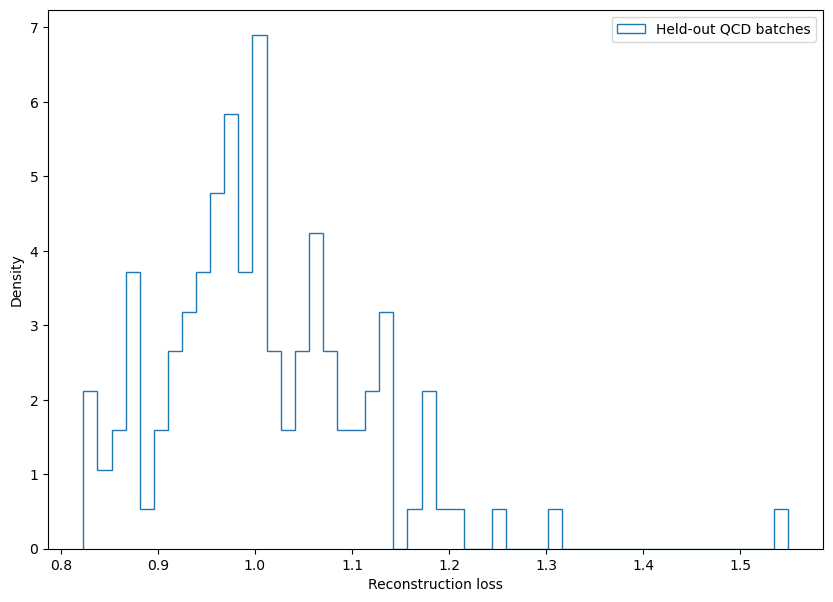

In [13]:
plt.hist(
    losses_testing_qcd,
    bins=50,
    histtype="step",
    label="Held-out QCD batches",
    density=True,
)
plt.xlabel("Reconstruction loss")
plt.ylabel("Density")
plt.legend()
plt.show()

Once we are happy with the model we trained, we can start inferencing it on whatever fresh data we need, be it signal or background. Since this new data will not have been processed before, we provide the `utils.RootGraphScorer` class that streams in events from a (list of) ROOT trees, calculates the corresponding graphs without persisting them on disk, evaluates the model, and returns the corresponding scores in an `ak.Array`.

To this end, we first need to define exactly how the training graphs were produced, in order to process the new data consistently. This is handled by the `utils.GraphBuilder` package:

In [14]:
from utils.GraphBuilder import GraphBuildConfig

config = GraphBuildConfig(
    jet_collection = "FatJet",
    use_lund_decomp = True,
    n_lund_vars = 5,
    save_energy_fractions = True,
    save_4vectors_in_lund_tree = False,
)

In [15]:
from utils.RootGraphScorer import RootGraphScorer
import os

scorer = RootGraphScorer(
    model=model,
    graph_config=config,
    normalizer=normalizer,
    max_jets=2,
    num_workers=4,
    worker_prefetch=2,
    root_entry_batch_size=1000,
    graph_batch_size=256,
    verbose=True,
)

files = os.listdir("test_data/")
scores = []
for file in files:
    if file.endswith(".root"):
        file_path = os.path.join("test_data/", file)
        score = scorer.score_file(file_path)
        scores.append(score)

Scoring QCD_HT700to1000presel.root: 100%|██████████| 11706/11706 [01:13<00:00, 159.76it/s]


We can check that, even though processing happened independently, the scores are consistent:

In [19]:
model.eval()

loss = model.score_event(qcd[0])
loss[0].item()

60.78666687011719

In [21]:
scores[1][0][0]

0.8304488658905029